In [1]:
# 爬虫人口迁徙综合分析
# 完成时间：2026-7-21~2026-7-22
# 练习内容：利用爬虫抓后台数据接口，完成数据处理和指标运算，并可视化

In [2]:
"""
5个核心环节
1爬虫方法论讲解：
解释动态网页的加载逻辑：网页数据不由 HTML 直接返回，而是通过 JavaScript 异步请求后台接口、再渲染到页面。
因此爬虫的核心思路是跳过页面渲染，直接抓后台数据接口，也就是 “抓包爬虫”。
2抓包实操教学：
演示 Chrome 开发者工具（F12）的 Network 面板使用：勾选 Preserve log 保留日志、筛选 XHR 请求、刷新页面定位数据接口。
最终找到百度迁徙的历史曲线接口 historycurve.jsonp，拆解接口参数（行政级别、城市 ID、迁入 / 迁出类型、JSONP 回调），
说明修改参数即可批量获取不同城市的数据。
3数据抓取代码实现用 Python 的requests包发送 HTTP 请求，获取 JSONP 格式的返回数据；讲解 JSONP 格式的解析方法 —— 去掉外层回调括号，
用json库转成 Python 字典，提取「日期 - 迁徙指数」的核心数据。
4数据处理与指标计算
用pandas将数据转为结构化表格，按年份拆分 2026 年和 2025 年；定义两个核心分析指标：
累积净迁徙流量：年初到当日累计迁入减去累计迁出，反映城市人口净增减趋势。
人口恢复率：以 7月为基准，计算后续人口回流的比例，量化复工进度。
5可视化与研究拓展
用matplotlib+seaborn绘制双轴对比图：柱状图展示累积净迁徙规模，折线图展示人口恢复率，直观对比疫情前后差异；

"""

'\n5个核心环节\n1爬虫方法论讲解：\n解释动态网页的加载逻辑：网页数据不由 HTML 直接返回，而是通过 JavaScript 异步请求后台接口、再渲染到页面。\n因此爬虫的核心思路是跳过页面渲染，直接抓后台数据接口，也就是 “抓包爬虫”。\n2抓包实操教学：\n手把手演示 Chrome 开发者工具（F12）的 Network 面板使用：勾选 Preserve log 保留日志、筛选 XHR 请求、刷新页面定位数据接口。\n最终找到百度迁徙的历史曲线接口 historycurve.jsonp，拆解接口参数（行政级别、城市 ID、迁入 / 迁出类型、JSONP 回调），\n说明修改参数即可批量获取不同城市的数据。\n3数据抓取代码实现用 Python 的requests包发送 HTTP 请求，获取 JSONP 格式的返回数据；讲解 JSONP 格式的解析方法 —— 去掉外层回调括号，\n用json库转成 Python 字典，提取「日期 - 迁徙指数」的核心数据。\n4数据处理与指标计算\n用pandas将数据转为结构化表格，按年份拆分 2026 年和 2025 年；定义两个核心分析指标：\n累积净迁徙流量：年初到当日累计迁入减去累计迁出，反映城市人口净增减趋势。\n人口恢复率：以 1 月 23 日（春节前人口谷底）为基准，计算后续人口回流的比例，量化复工进度。\n5可视化与研究拓展\n用matplotlib+seaborn绘制双轴对比图：柱状图展示累积净迁徙规模，折线图展示人口恢复率，直观对比疫情前后差异；\n最后布置作业，引导拓展到全国城市，探究城市规模、地理位置对人口恢复速度的影响。\n\n'

开始抓取

In [8]:
import requests
import json
import pandas as pd

# ========== 1. 配置参数 ==========
# 储存抓取到的数据，并把callback后面的内容删掉，为了让接口返回的内容尽可能接近纯 JSON，方便 Python 直接解析，省去处理多余函数名的步骤
url = "https://huiyan.baidu.com/migration/historycurve.jsonp?dt=province&id=110000&type=move_in&callback="

# 请求参数（字典里详细的键可在上一步抓取的url里找到）
params = {
    "dt": "city",       # 市级数据
    "id": "110000",     # 城市编码，这里是北京
    "type": "move_in",  # move_in=迁入，move_out=迁出
    "callback": ""      # 回调函数留空，减少解析步骤
}

# 模拟浏览器请求头，不加大概率会被拦截
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36",
    "Referer": "https://qianxi.baidu.com/"
}

# ========== 2. 发送请求 ==========
response = requests.get(url, params=params, headers=headers)
# params=params：自动把字典里的键值对转换成 key=value 格式，用 & 拼接后自动加到 url 末尾，生成完整的请求地址
# headers=headers：伪装成正常浏览器，绕过最基础的反爬检测

# 拿到原始字符串
raw_text = response.text
# raw_text 看看长什么样，太长了先注释掉

In [4]:
# ========== 3. 解析JSONP数据 ==========
# 观察raw_text发现首尾处的"()"不是json语法的一部分，直接解析会报错，所以需要对百度迁徙接口返回的原始文本做两步清洗
# 先去掉字符串首尾的空白字符（换行、空格、制表符等）
# 再因为callback留空后，返回的是 (...)，直接切片去掉首尾括号
json_str = raw_text.strip()[1:-1]

# 把JSON格式字符串转成Python字典，以便提取数据
data_dict = json.loads(json_str)
# loads() / dumps()：处理字符串和 Python 对象的互转
# load() / dump()：处理文件和 Python 对象的互转

# 取出核心数据
# 抓包相关请求后，切换到预览选项，最开始只能看到最外层的 3 个键：errno、errmsg、data，errno 和 errmsg 是状态信息（成功 / 失败提示），
# 不是我们要的迁徙数据，直接排除；只有 data 是专门存放业务数据的容器，所以第一层确定取 ["data"]。点击 data 前面的小三角展开，
# 就能看到里面只有一个键 list，所有日期、对应的迁徙数值，全都存在 list 里；所以第二层确定取 ["list"]
daily_data = data_dict["data"]["list"]

# ========== 4. 转成表格方便后续计算 ==========
df = pd.DataFrame(
    list(daily_data.items()), # .items()返回字典中所有的键值对，每个日期和对应的指数，被打包成一个元组，整体是一个可迭代的键值对集合
    # 外面包层list()把可迭代对象转换成列表，因为Pandas 的 DataFrame 构造函数，接收「由元组 / 列表组成的列表」时，会把每个元组当成一行，
    # 元组里的每个元素当成一列。这正好符合我们的需求：一行代表一天，两列分别是日期和迁徙指数
    columns=["date", "migration_index"] # columns指定列名，按顺序存储元组的两个值
)

# 把日期字符串转成标准日期格式，后续计算更方便
df["date"] = pd.to_datetime(df["date"], format="%Y%m%d")
# pd.to_datetime()是官方提供的日期解析函数，作用是把符合日期格式的字符串 / 数字，转换成 Pandas 专属的 datetime64 日期类型
# 因为只有转成日期类型后，才能做各种时间相关操作：按年月筛选、计算时间差、按周 / 月分组、画图时自动识别时间坐标轴等
# 如果一直用字符串格式的日期，虽然肉眼能看懂，但 Pandas 无法识别时间逻辑，很多时间序列功能都用不了
# format="%Y%m%d"是告诉 Pandas 这个字符串是「4 位年 + 2 位月 + 2 位日」的结构

# 按日期排序
df = df.sort_values("date").reset_index(drop=True) # .reset_index(drop=True)：排序之后，每一行原来的索引（0、1、2...）会跟着行一起打乱，
# 变成乱序的数字。reset_index() 的作用就是重新生成从 0 开始、连续递增的行索引，如果不加 drop=True，重置索引时会把旧的乱序索引变成一个新列
#（列名叫 index），这列数据没有实际用处，还会占用空间；加上 drop=True 就会直接丢弃旧索引，只保留全新的连续索引

print(df.head())

        date  migration_index
0 2019-01-12         7.665062
1 2019-01-13         7.804544
2 2019-01-14        11.013440
3 2019-01-15         8.218357
4 2019-01-16         7.895264


集中配置常量

In [5]:
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 把爬虫里所有会变动的参数（城市、年份、基准日、请求头、接口地址）全部抽成全局常量，统一放在代码开头
# 后续切换城市、更换对比年份、调整基准日期时，只需要修改这里的数值，不用去业务逻辑代码里四处查找改动

# ===================== 1. 基础配置（已更新至2026年7月最新） =====================
# 目标城市：以北京市为例，编码110000，换城市只需修改这两个值
CITY_ID = "110000"
CITY_NAME = "北京市"

# 对比年份：今年2026，去年2025（同期对比）
YEAR_CURRENT = 2026
YEAR_LAST = 2025

# 人口恢复率基准日：取每年除夕（春节前一天），可自行修改为任意日期
BASE_DATE_CURRENT = "2026-02-16"  # 2026年除夕
BASE_DATE_LAST = "2025-01-28"     # 2025年除夕

# 请求头：模拟浏览器身份，必须携带否则易被拦截返回403
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36",
    "Referer": "https://qianxi.baidu.com/"
}

# 百度迁徙历史曲线接口（抓包所得）
API_URL = "https://huiyan.baidu.com/migration/historycurve.jsonp"


# ===================== 2. 封装数据抓取函数 =====================
def get_migration_data(city_id, move_type):
    """
    获取单城市单类型的迁徙历史数据
    :param city_id: 城市6位行政区划代码
    :param move_type: move_in=迁入，move_out=迁出
    :return: 整理好的DataFrame，包含日期、迁徙指数、年份、年内天数
    """
    # 构造请求参数
    params = {
        "dt": "city",
        "id": city_id,
        "type": move_type,
        "callback": ""  # 回调函数留空，简化JSONP解析
    }
    
    # 发送请求
    response = requests.get(API_URL, params=params, headers=HEADERS)
    raw_text = response.text.strip()
    
    # 解析JSONP：去掉外层括号，提取纯JSON字符串
    json_str = raw_text[1:-1]
    data_dict = json.loads(json_str)
    
    # 提取核心的「日期:指数」字典
    daily_data = data_dict["data"]["list"]
    
    # 转成DataFrame表格
    df = pd.DataFrame(
        list(daily_data.items()),
        columns=["date_str", "index"]
    )
    
    # 日期字符串转标准日期格式
    df["date"] = pd.to_datetime(df["date_str"], format="%Y%m%d")
    # 按日期升序排序
    df = df.sort_values("date").reset_index(drop=True)
    # 增加年份字段
    df["year"] = df["date"].dt.year
    # 增加「年内第几天」，用于跨年对齐对比
    df["day_of_year"] = df["date"].dt.dayofyear
    
    return df


# ===================== 3. 抓取迁入+迁出全量数据 =====================
# 分别抓取迁入、迁出数据
df_in = get_migration_data(CITY_ID, "move_in")
df_out = get_migration_data(CITY_ID, "move_out")

# 按日期合并迁入和迁出，同一天数据放在一行
df_all = pd.merge( #  .merge()以日期为键，把两张表拼成一张，让同一天的迁入指数、迁出指数落在同一行
    df_in[["date", "year", "day_of_year", "index"]],  # 合并的左表（迁入数据表），没有传入整张表，只主动选取了 4 个必要的列
    df_out[["date", "index"]],  # 这是合并的右表（迁出数据表），只保留了 2 列
    on="date",  # 指定两张表按 date 列进行匹配合并，只有两张表中 date 值完全相同的行，才会被拼接到同一行,merge默认内连接，即只保留两边都存在的日期
    suffixes=("_in", "_out") # 两张表里都有一个叫 index 的列，直接合并会出现列名冲突，左表（迁入）重命名为 index_in。右表（迁出）重命名为 index_out
)



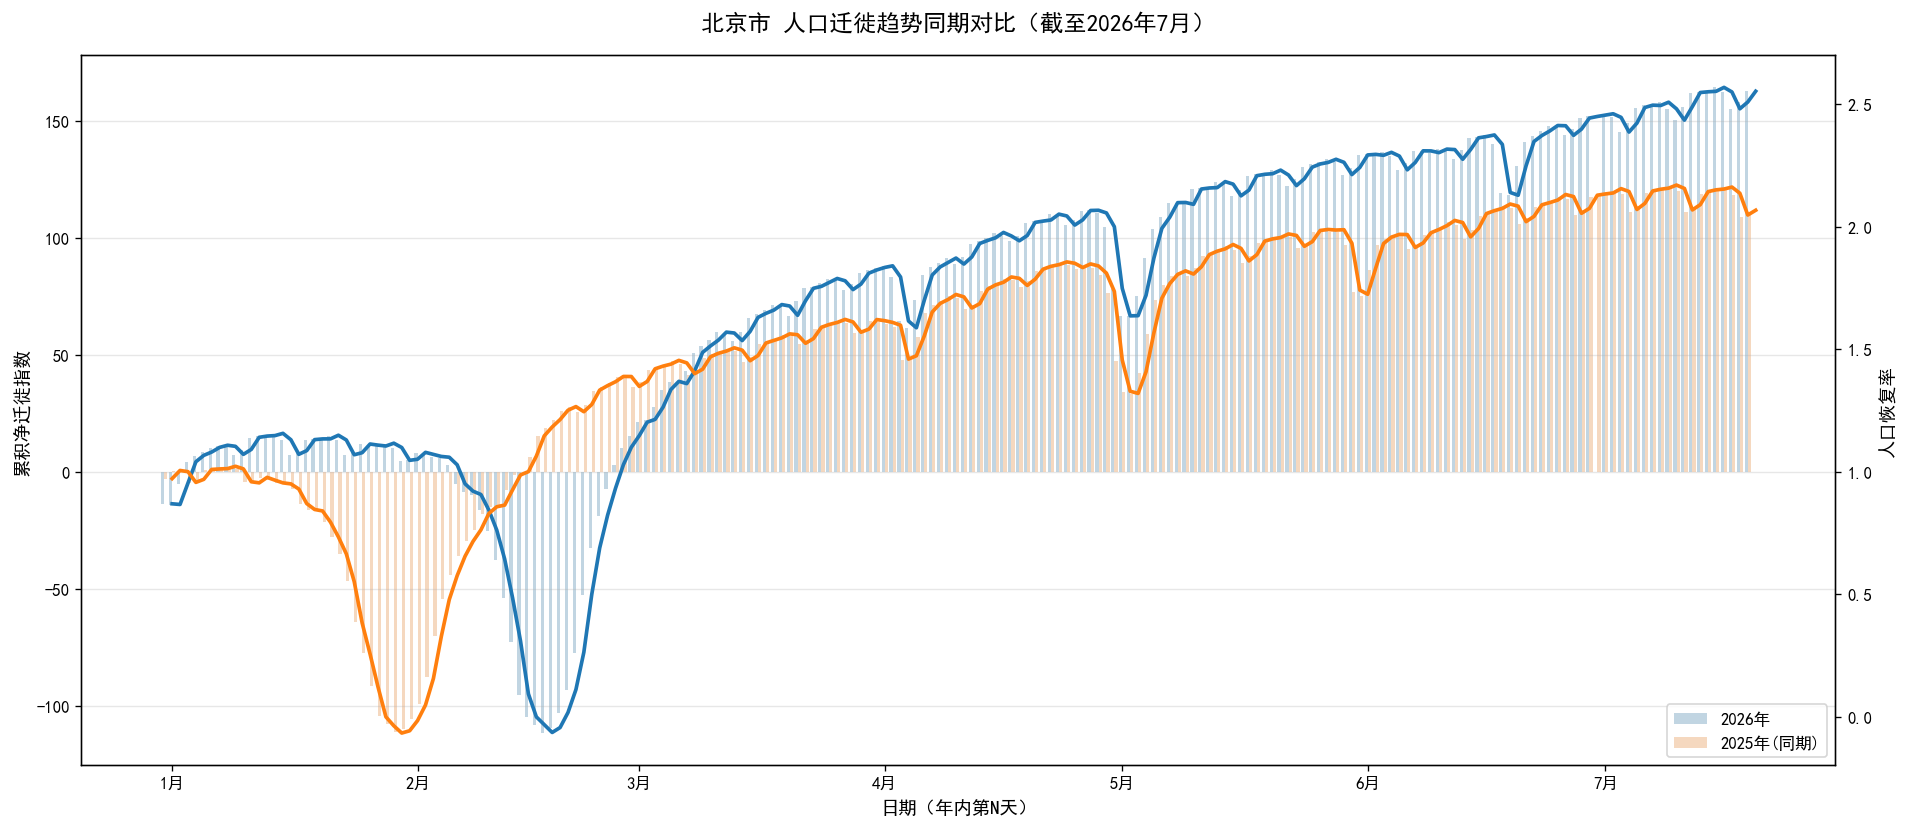

In [6]:

# ===================== 4. 指标计算函数 =====================
def calc_year_metrics(df_year, base_date_str):
    """
    按日期定位基准日，计算累积净流量与人口恢复率
    :param df_year: 单一年份数据
    :param base_date_str: 基准日日期字符串 YYYY-MM-DD
    """
    df_year = df_year.sort_values("date").reset_index(drop=True) # 先按日期升序排列，再重置为从 0 开始的连续行索引

    # 计算累计迁入、迁出、净流量 .cumsum() 是 Pandas 的累计求和函数（cumulative sum），会从第一行开始，逐行累加当前行及之前所有行的数值
    df_year["cum_in"] = df_year["index_in"].cumsum() # 从数据起始日到当天，累计的总迁入规模指数
    df_year["cum_out"] = df_year["index_out"].cumsum() # 计算从起始日到当天的累计总迁出规模指数
    df_year["net_flow"] = df_year["cum_in"] - df_year["cum_out"] # 累计迁入 减去 累计迁出，得到累计净流量

    # 按日期精准找基准值，彻底替代硬编码行号
    base_date = pd.to_datetime(base_date_str) # 把传入的字符串格式的基准日，转换成 Pandas 的 datetime 日期类型，和表里的 date 列类型保持一致，才能准确匹配
    base_net = df_year.loc[df_year["date"] == base_date, "net_flow"].iloc[0]
    # df_year["date"] == base_date：生成布尔序列，日期等于基准日的行为 True
    # .loc[条件, 列名]：筛选出符合条件的行，取出指定的 net_flow 列
    # .iloc[0]：取出结果里的第一个值（因为日期唯一，只会有一行），最终得到基准日当天的累计净流量数值

    # 计算人口恢复率
    df_year["recovery_rate"] = (df_year["net_flow"] - base_net) / abs(base_net) 
    # 分子：当日累计净流量 减去 基准日净流量，代表从谷底回流了多少人口规模 分母：基准日净流量的绝对值
    df_year["day_index"] = df_year.index
    return df_year


# ===================== 5. 分年份计算 + 同期对齐 =====================
# 获取两年的迁入迁出合并数据
df_current = df_all[df_all["year"] == YEAR_CURRENT].copy() #
df_last = df_all[df_all["year"] == YEAR_LAST].copy()
# df_all["year"] == YEAR_CURRENT 会生成一列布尔值，年份等于目标年份的行为 True
# 把布尔序列放进方括号 df_all[条件]，就会筛选出所有符合条件的行，得到单一年份的数据子集
# .copy() 是强制生成一份独立的新副本，因为后续如果直接在筛选结果上更改列容易引起报错

# 同期截断：以今年数据长度为准，保证对比公平
max_day = df_current["day_of_year"].max() # 取出当前年数据里，最晚的一天是当年的第几天
df_last = df_last[df_last["day_of_year"] <= max_day].copy() # 只保留对照年同期范围内的数据，丢弃后面超出的部分
# 通常当前年的数据是不完整的（比如现在是 7 月，只有 1-7 月的数据），而对照年有全年完整数据。如果直接拿半年数据和全年数据对比，无论是曲线长度还是恢复程度都会不公平。
# 用 day_of_year 做截断后，两年都只对比相同时间跨度内的走势，保证「同期对比」的严谨性，对应教程里「农历同期对比」的设计思想

# 计算指标
df_current = calc_year_metrics(df_current, BASE_DATE_CURRENT)
df_last = calc_year_metrics(df_last, BASE_DATE_LAST)

# 新增图例标签
df_current["year_label"] = f"{YEAR_CURRENT}年"
df_last["year_label"] = f"{YEAR_LAST}年(同期)"

# 纵向拼接两张表
df_plot = pd.concat([df_current, df_last], ignore_index=True)
# pd.concat() 是 Pandas 的数据拼接函数，传入一个 DataFrame 列表，默认按纵向（行方向）拼接，把两张表上下叠在一起
# ignore_index=True：拼接后重新生成从 0 开始的连续行索引，丢弃原来两张表各自的旧索引，避免索引重复、混乱


# ===================== 6. 双轴可视化 =====================
# 全局字体配置：解决中文与负号显示异常
# Matplotlib 默认使用的字体是 DejaVu Sans，这个字体只包含英文字母、数字和符号，没有任何中文字形。
# 如果不修改字体，图表里的中文标题、坐标轴标签、图例文字，都会全部显示成一个个小方块
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
# plt.rcParams这是 Matplotlib 的全局配置字典，用来统一修改绘图的默认参数。修改后当前脚本里的所有图表都会生效，不用每张图单独设置字体
# font.sans-serif这个配置项用来指定「无衬线字体」的优先查找列表：系统会按从左到右的顺序找字体，前面的字体存在就用前面的，找不到就自动用后面的，属于兜底兼容的写法
# SimHei是 Windows 系统自带的「黑体」，中文兼容性最好，是最常用的绘图中文字体；Microsoft YaHei是 Windows 系统自带的「微软雅黑」，显示效果更现代，作为第二备选

# 关闭 Unicode 负号，解决负号显示方块
plt.rcParams["axes.unicode_minus"] = False
# axes.unicode_minus 用来控制：坐标轴上的负数刻度，是否使用 Unicode 标准的负号字符
# 默认值是 True：使用 Unicode 专属负号，排版更规范；设为 False：改用普通的 ASCII 减号 - 来显示负数

plt.figure(figsize=(16, 7), dpi=120)
ax1 = plt.gca()

# 左轴：累积净迁徙指数（柱状图）
sns.barplot(
    data=df_plot,
    x="day_of_year",
    y="net_flow",
    hue="year_label",
    alpha=0.3,
    ax=ax1
)
ax1.set_ylabel("累积净迁徙指数", fontsize=11)
ax1.set_xlabel("日期（年内第N天）", fontsize=11)
ax1.grid(axis="y", alpha=0.3)

# 右轴：人口恢复率（折线图）
ax2 = ax1.twinx() # twinx() 是 Matplotlib 双轴绘图的核心函数，作用是创建一个和左轴共享 x 轴、但拥有独立 y 轴的新坐标轴
sns.lineplot( # 折线图函数
    data=df_plot,
    x="day_of_year",
    y="recovery_rate",
    hue="year_label",
    linewidth=2.2,
    ax=ax2,
    legend=False # 关闭折线图自身的图例。因为柱状图已经有按年份分组的图例了，再生成一份会重复，这里关闭后统一用左轴的图例
)
ax2.set_ylabel("人口恢复率", fontsize=11)

# x轴按月显示刻度，x 轴原本是「年内第几天」的数字，这部分把刻度替换成月份文字，提升可读性
month_ticks = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335] # 手动列出每个月 1 号对应的年内天数（2 月 1 日是第 32 天），作为刻度的位置
month_labels = ["1月", "2月", "3月", "4月", "5月", "6月", "7月", "8月", "9月", "10月", "11月", "12月"]

# 从预设的 12 个月份刻度里，筛选出「落在当前数据时间范围内」的月份索引，只保留有数据对应的月份刻度，避免 x 轴显示一堆没有数据的空月份标签
valid_idx = [i for i, day in enumerate(month_ticks) if day <= max_day]
# enumerate() 是 Python 内置函数，作用是同时遍历列表的「索引位置」和「元素值」
# i：当前元素的索引下标（从 0 开始，0 对应 1 月，1 对应 2 月，…，11 对应 12 月）;day：当前元素的值，也就是该月 1 号对应的年内天数
# if day <= max_day只有当这个月的起始天数，不超过数据的最后一天时，这个月份才保留

ax1.set_xticks([month_ticks[i] for i in valid_idx])
ax1.set_xticklabels([month_labels[i] for i in valid_idx])

# 标题与图例
plt.title(f"{CITY_NAME} 人口迁徙趋势同期对比（截至2026年7月）", fontsize=14, pad=15)
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(handles1, labels1, loc="lower right")

plt.tight_layout()
plt.show()